# Разведочный анализ данных

Датасет: Seoul Bike Sharing Demand, UCI

Одна строка — один час работы велопроката в Сеуле. Цель — исследовать спрос и его связь с погодой и временем.

### 1. Загрузка данных и библиотек

In [ ]:
!pip install -q ucimlrepo

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=560)
df = dataset.data.original

df.head()

,Date,Rented Bike Count,Hour,Temperature,Humidity,Wind speed,Visibility,Dew point temperature,Solar Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning Day
0,1/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,1/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,1/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,1/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,1/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


### 2. Общая информация и описание признаков

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   8760 non-null   object 
 1   Rented Bike Count      8760 non-null   int64  
 2   Hour                   8760 non-null   int64  
 3   Temperature            8760 non-null   float64
 4   Humidity               8760 non-null   int64  
 5   Wind speed             8760 non-null   float64
 6   Visibility             8760 non-null   int64  
 7   Dew point temperature  8760 non-null   float64
 8   Solar Radiation        8760 non-null   float64
 9   Rainfall               8760 non-null   float64
 10  Snowfall               8760 non-null   float64
 11  Seasons                8760 non-null   object 
 12  Holiday                8760 non-null   object 
 13  Functioning Day        8760 non-null   object 
dtypes: float64(6), int64(4), object(4)
memory usage: 958.3+ 

| Столбец | Значение |
|---|---|
| `Date` | Дата наблюдения в формате день/месяц/год. |
| `Rented Bike Count` | Целевая переменная: число аренд за час. |
| `Hour` | Час суток от 0 до 23. |
| `Temperature(°C)` | Температура воздуха в °C. |
| `Humidity(%)` | Относительная влажность воздуха в %. |
| `Wind speed (m/s)` | Скорость ветра в м/с. |
| `Visibility (10m)` | Видимость в десятках метров: 2000 соответствует 20 км. |
| `Dew point temperature(°C)` | Температура точки росы в °C. |
| `Solar Radiation (MJ/m2)` | Солнечная радиация в МДж/м². |
| `Rainfall(mm)` | Количество дождевых осадков в мм. |
| `Snowfall (cm)` | Количество снега в см. |
| `Seasons` | Сезон: Winter, Spring, Summer или Autumn. |
| `Holiday` | Праздник (Holiday) или обычный день (No Holiday). |
| `Functioning Day` | Работал ли прокат в этот час: Yes или No. |

In [ ]:
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
target = 'Rented Bike Count'
numeric_features = ['Hour', 'Temperature', 'Humidity', 'Wind speed',
                    'Visibility', 'Dew point temperature',
                    'Solar Radiation', 'Rainfall', 'Snowfall']
category_features = ['Seasons', 'Holiday', 'Functioning Day']

print(f"Размер: {df.shape}")
print(f"Период: {df['Date'].min().date()} - {df['Date'].max().date()}")

Размер: (8760, 14)
Период: 2017-12-01 - 2018-11-30


In [ ]:
df[numeric_features + [target]].describe().round(2)

,Hour,Temperature,Humidity,Wind speed,Visibility,Dew point temperature,Solar Radiation,Rainfall,Snowfall,Rented Bike Count
count,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00,8760.00
mean,11.50,12.88,58.23,1.72,1436.83,4.07,0.57,0.15,0.08,704.60
std,6.92,11.94,20.36,1.04,608.30,13.06,0.87,1.13,0.44,645.00
min,0.00,-17.80,0.00,0.00,27.00,-30.60,0.00,0.00,0.00,0.00
25%,5.75,3.50,42.00,0.90,940.00,-4.70,0.00,0.00,0.00,191.00
50%,11.50,13.70,57.00,1.50,1698.00,5.10,0.01,0.00,0.00,504.50
75%,17.25,22.50,74.00,2.30,2000.00,14.80,0.93,0.00,0.00,1065.25
max,23.00,39.40,98.00,7.40,2000.00,27.20,3.52,35.00,8.80,3556.00


### 3. Качество данных

In [ ]:
print("Пропуски по столбцам:")
print(df.isna().sum())

Пропуски по столбцам:
Date                     0
Rented Bike Count        0
Hour                     0
Temperature              0
Humidity                 0
Wind speed               0
Visibility               0
Dew point temperature    0
Solar Radiation          0
Rainfall                 0
Snowfall                 0
Seasons                  0
Holiday                  0
Functioning Day          0
dtype: int64


Посмотрим на некорректные данные

In [ ]:
print(f"Полные дубликаты: {df.duplicated().sum()}")
print(f"Повторы даты и часа: {df.duplicated(subset=['Date', 'Hour']).sum()}")
print(f"Отрицательная аренда: {(df[target] < 0).sum()}")
print(f"Некорректные часы: {(~df['Hour'].between(0, 23)).sum()}")
print(f"Влажность вне [0, 100]: {(~df['Humidity'].between(0, 100)).sum()}")
print(f"Нулевая влажность: {(df['Humidity'] == 0).sum()}")
print(f"Нулевые значения аренды: {(df[target] == 0).sum()}")

Полные дубликаты: 0
Повторы даты и часа: 0
Отрицательная аренда: 0
Некорректные часы: 0
Влажность вне [0, 100]: 0
Нулевая влажность: 17
Нулевые значения аренды: 295


Проверим, что в нерабочие дни количество арендованных велосипедов нулевое

In [ ]:
df.groupby('Functioning Day')[target].agg(['count', 'min', 'mean', 'max']).round(2)

,count,min,mean,max
Functioning Day,,,,
No,295,0,0.00,0
Yes,8465,2,729.16,3556


Пропусков, дубликатов и потерянных часов нет, поэтому заполнять и удалять строки не требуется. Сохраним в `active` датасет только с рабочими часами.

In [ ]:
active = df[df['Functioning Day'] == 'Yes'].copy()
print(f"Работающий прокат: {len(active)} часов")

Работающий прокат: 8465 часов


### 4. Распределение целевой переменной

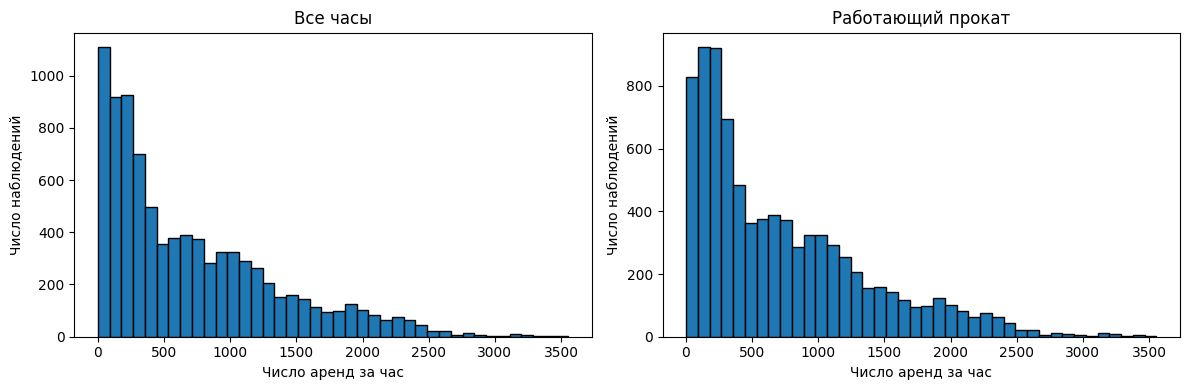

,Rented Bike Count
count,8465.00
mean,729.16
std,642.35
min,2.00
25%,214.00
50%,542.00
75%,1084.00
max,3556.00


In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df[target], bins=40, edgecolor='black')
plt.title('Все часы')
plt.xlabel('Число аренд за час')
plt.ylabel('Число наблюдений')

plt.subplot(1, 2, 2)
plt.hist(active[target], bins=40, edgecolor='black')
plt.title('Работающий прокат')
plt.xlabel('Число аренд за час')
plt.ylabel('Число наблюдений')

plt.tight_layout()
plt.show()

active[target].describe().round(2)

Распределение имеет правый хвост: высокие значения аренды встречаются реже низких.

### 5. Распределения остальных признаков

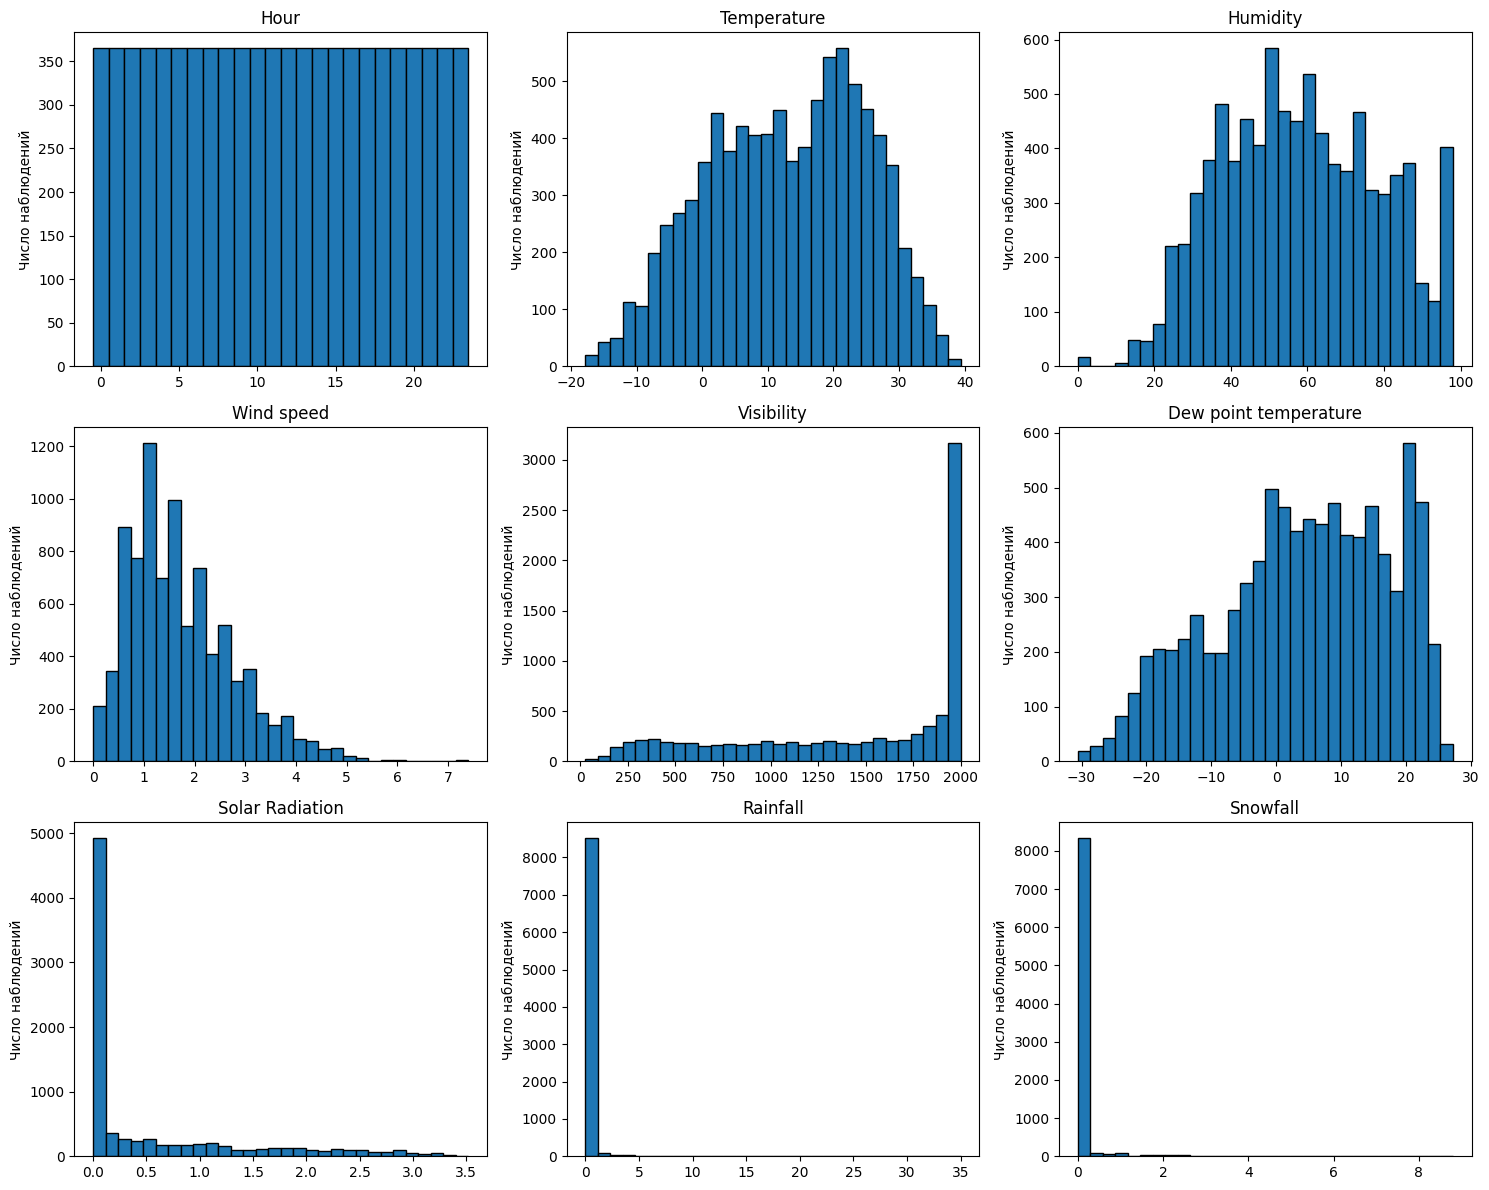

In [ ]:
plt.figure(figsize=(15, 12))
for i, feature in enumerate(numeric_features):
    plt.subplot(3, 3, i + 1)
    if feature == 'Hour':
        plt.hist(df[feature], bins=np.arange(-0.5, 24.5, 1), edgecolor='black')
    else:
        plt.hist(df[feature], bins=30, edgecolor='black')
    plt.title(feature)
    plt.ylabel('Число наблюдений')

plt.tight_layout()
plt.show()

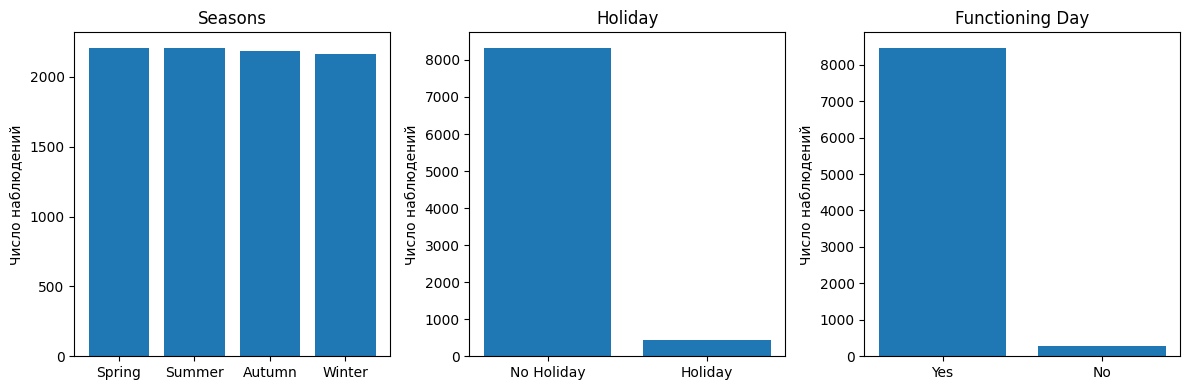

In [ ]:
plt.figure(figsize=(12, 4))
for i, feature in enumerate(category_features):
    plt.subplot(1, 3, i + 1)
    counts = df[feature].value_counts()
    plt.bar(counts.index, counts.values)
    plt.title(feature)
    plt.ylabel('Число наблюдений')

plt.tight_layout()
plt.show()

Каждый час представлен одинаково, в каждой дате 24 записи. Сезоны почти сбалансированы.
Праздничных часов гораздо меньше обычных. Дождь и снег чаще равны нулю, их распределения имеют длинный правый хвост.

### 6. Корреляции признаков

In [ ]:
corr = active[numeric_features + [target]].corr()
target_corr = pd.DataFrame({
    'Пирсон': corr[target].drop(target)
})
target_corr.sort_values('Пирсон', ascending=False).round(3)

,Пирсон
Temperature,0.563
Hour,0.425
Dew point temperature,0.400
Solar Radiation,0.274
Visibility,0.212
Wind speed,0.125
Rainfall,-0.129
Snowfall,-0.152
Humidity,-0.202


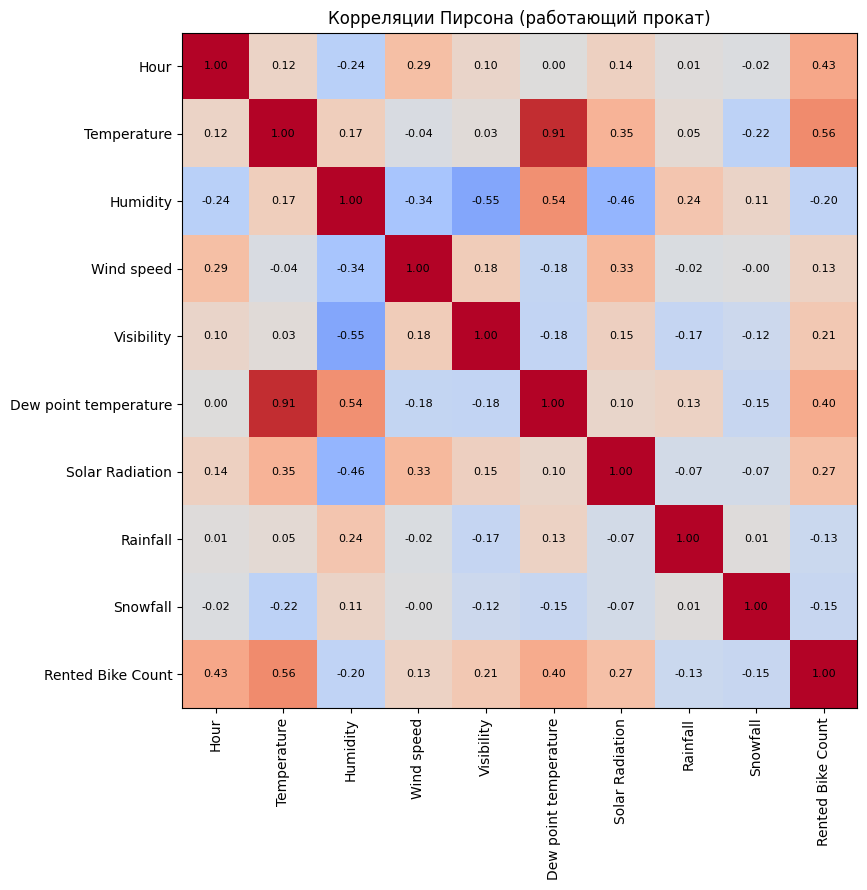

In [ ]:
plt.figure(figsize=(12, 9))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.title("Корреляции Пирсона (работающий прокат)")
plt.tight_layout()
plt.show()

Наиболее сильная положительная корреляция с арендой у температуры (0.56); у часа суток 0.43.
Температура и точка росы сильно связаны между собой (0.91). Дождь, снег и влажность связаны с арендой отрицательно.

### 7. Зависимости целевой переменной от каждого признака

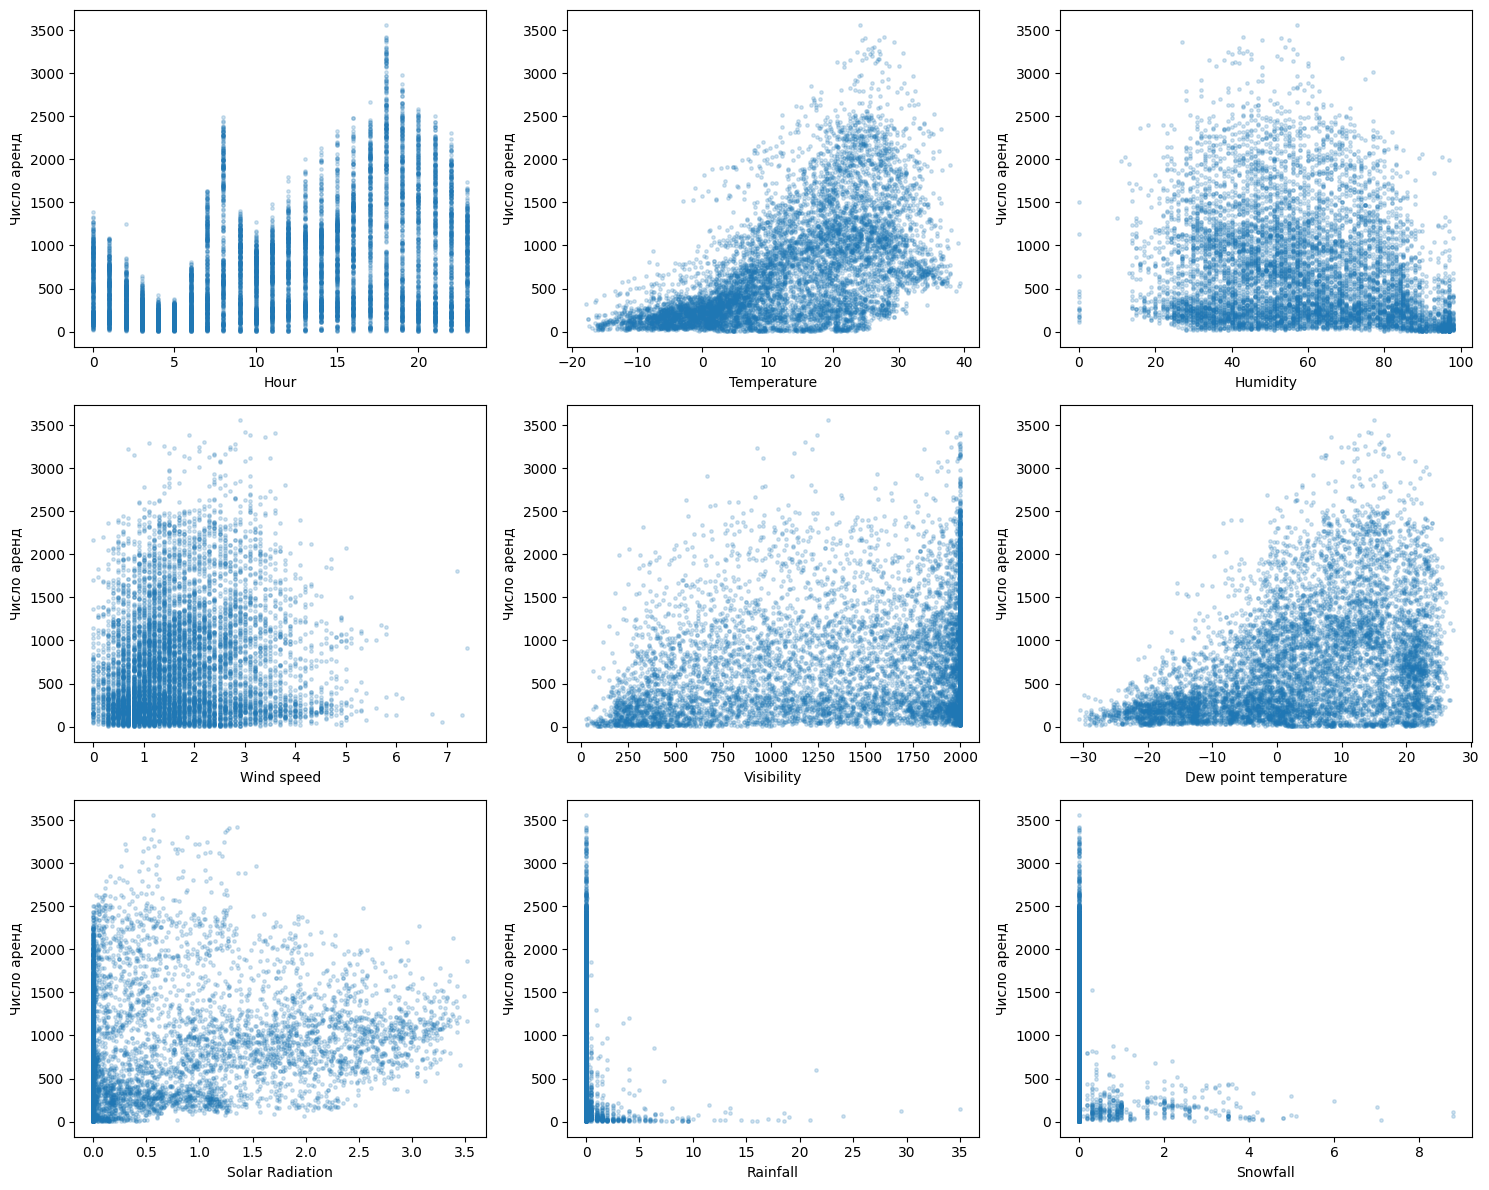

In [ ]:
plt.figure(figsize=(15, 12))
for i, feature in enumerate(numeric_features):
    plt.subplot(3, 3, i + 1)
    plt.scatter(active[feature], active[target], s=6, alpha=0.2)
    plt.xlabel(feature)
    plt.ylabel('Число аренд')

plt.tight_layout()
plt.show()

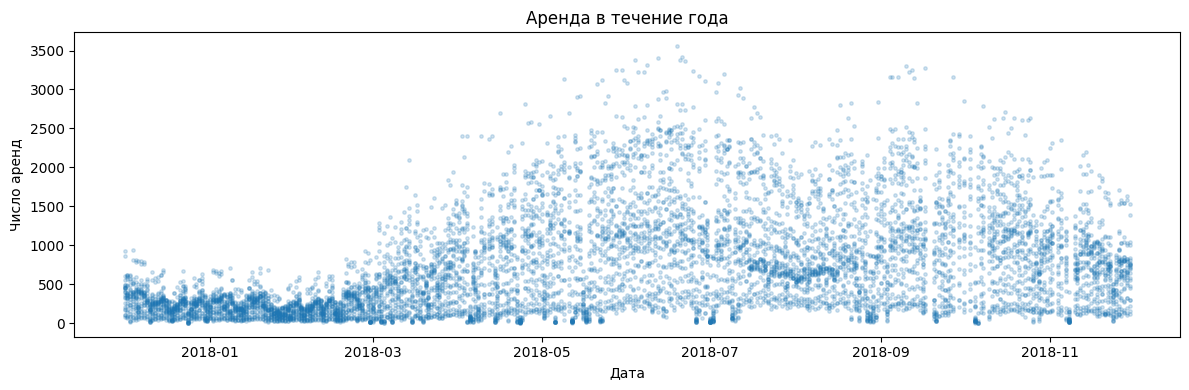

In [ ]:
plt.figure(figsize=(12, 4))
plt.scatter(active['Date'], active[target], s=6, alpha=0.2)
plt.xlabel('Дата')
plt.ylabel('Число аренд')
plt.title('Аренда в течение года')
plt.tight_layout()
plt.show()

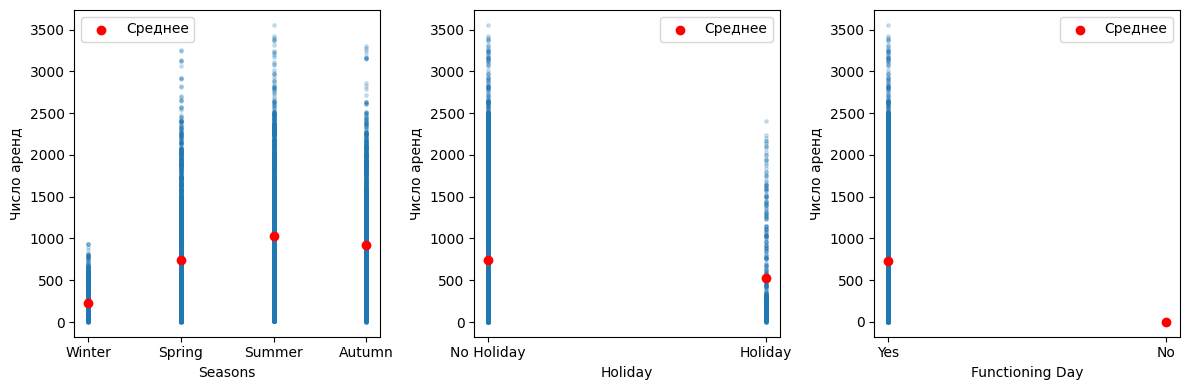

In [ ]:
category_order = {
    'Seasons': ['Winter', 'Spring', 'Summer', 'Autumn'],
    'Holiday': ['No Holiday', 'Holiday'],
    'Functioning Day': ['Yes', 'No']
}

plt.figure(figsize=(12, 4))
for i, feature in enumerate(category_features):
    plt.subplot(1, 3, i + 1)
    data = df if feature == 'Functioning Day' else active
    labels = category_order[feature]
    positions = {label: j for j, label in enumerate(labels)}
    plt.scatter(data[feature].map(positions), data[target], s=6, alpha=0.2)
    means = data.groupby(feature)[target].mean().reindex(labels)
    plt.scatter(range(len(labels)), means.values, color='red', label='Среднее')
    plt.xticks(range(len(labels)), labels)
    plt.xlabel(feature)
    plt.ylabel('Число аренд')
    plt.legend()

plt.tight_layout()
plt.show()

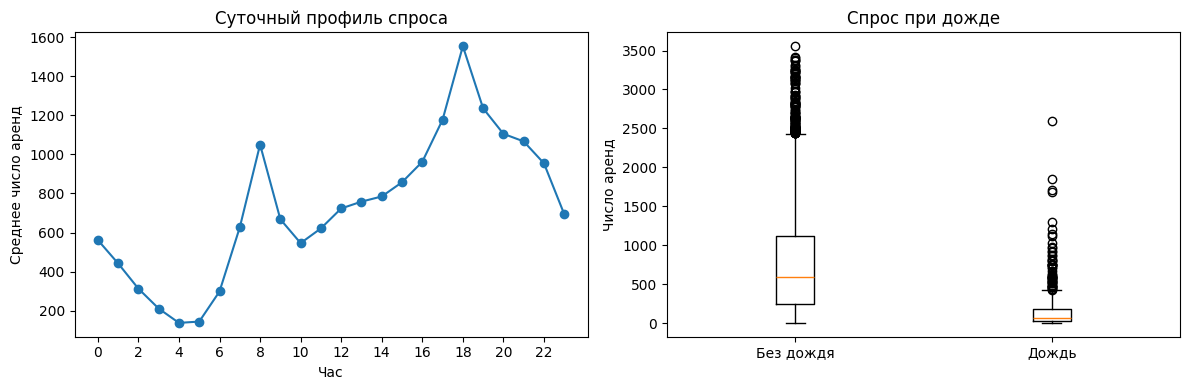

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
hour_mean = active.groupby('Hour')[target].mean()
plt.plot(hour_mean.index, hour_mean.values, marker='o')
plt.xticks(range(0, 24, 2))
plt.xlabel('Час')
plt.ylabel('Среднее число аренд')
plt.title('Суточный профиль спроса')

plt.subplot(1, 2, 2)
rainy = active['Rainfall'] > 0
plt.boxplot([active.loc[~rainy, target], active.loc[rainy, target]],
            tick_labels=['Без дождя', 'Дождь'])
plt.ylabel('Число аренд')
plt.title('Спрос при дожде')

plt.tight_layout()
plt.show()

In [ ]:
print('Средние по сезонам:')
print(active.groupby('Seasons')[target].mean().round(2))
print('Среднее без дождя:', round(active.loc[~rainy, target].mean(), 2))
print('Среднее при дожде:', round(active.loc[rainy, target].mean(), 2))

Средние по сезонам:
Seasons
Autumn     924.11
Spring     746.25
Summer    1034.07
Winter     225.54
Name: Rented Bike Count, dtype: float64

Среднее без дождя: 765.63
Среднее при дожде: 167.26


- Спрос выше в тёплые месяцы: зимой 226, летом 1034 аренды за час; рост с температурой не строго линейный.
- Есть утренний пик около 8:00 и более высокий вечерний около 18:00; минимум около 4:00.
- При дожде спрос ниже: в среднем 167 против 766 без дождя.
- В праздники средний спрос ниже, однако состав сезонов и погоды может различаться. Связь с ветром и видимостью слабее.

### 8. Проверка статистических гипотез

In [ ]:
daily = active.groupby('Date').agg({
    'Rented Bike Count': 'mean',
    'Temperature': 'mean',
    'Holiday': 'first',
    'Hour': 'count'
})
daily = daily[daily['Hour'] == 24]

alpha = 0.05

Сравнение спроса в 18:00 и 4:00. (t-критерий Стьюдента)
- H0: средняя разность не положительна.
- H1: средняя разность положительна.

In [ ]:
hour_table = active.pivot(
    index='Date',
    columns='Hour',
    values='Rented Bike Count'
)
hour_table = hour_table.loc[daily.index]

difference = hour_table[18] - hour_table[4]

n = len(difference)
mean_difference = difference.mean()
std_difference = difference.std(ddof=1)

# Одновыборочная t-статистика
t_stat = mean_difference / (std_difference / np.sqrt(n))
p_value = stats.t.sf(t_stat, df=n - 1)

print('Спрос в 18:00 и 4:00')
print(f'Среднее в 18:00: {hour_table[18].mean():.1f}')
print(f'Среднее в 4:00: {hour_table[4].mean():.1f}')
print(f'Средняя разность: {mean_difference:.1f}')
print(f't-статистика: {t_stat:.3f}')
print(f'p-value: {p_value:.3e}')

if p_value < alpha:
    print('H0 отклоняется по приближённому тесту: средняя разность положительна.')
else:
    print('Нет оснований отклонить H0.')

Спрос в 18:00 и 4:00
Среднее в 18:00: 1552.7
Среднее в 4:00: 137.5
Средняя разность: 1415.2
t-статистика: 27.425
p-value: 1.353e-89
H0 отклоняется по приближённому тесту: средняя разность положительна.


Сравнение долей дней с высоким (>500) спросом. (Хи-квадрат критерий)
- H0: доли таких дней в праздники и обычные дни одинаковы.
- H1: доли различаются.

In [ ]:
threshold = 500

holiday = daily[daily['Holiday'] == 'Holiday']['Rented Bike Count']
regular = daily[daily['Holiday'] == 'No Holiday']['Rented Bike Count']

high_holiday = (holiday >= threshold).sum()
high_regular = (regular >= threshold).sum()

table = np.array([
    [high_holiday, len(holiday) - high_holiday],
    [high_regular, len(regular) - high_regular]
])

chi2_stat, p_value, degrees, expected = stats.chi2_contingency(
    table, correction=False
)

print("Высокий спрос в праздники и обычные дни")
print(f"Праздники: {high_holiday} из {len(holiday)}, "
      f"доля = {high_holiday / len(holiday):.3f}")
print(f"Обычные дни: {high_regular} из {len(regular)}, "
      f"доля = {high_regular / len(regular):.3f}")
print(f"хи-квадрат-статистика: {chi2_stat:.3f}")
print(f"p-value: {p_value:.3e}")

if p_value < alpha:
    print("H0 отклоняется по тесту: доли различаются.")
else:
    print("Нет оснований отклонить H0: различие долей незначимо.")

Высокий спрос в праздники и обычные дни
Праздники: 8 из 17, доля = 0.471
Обычные дни: 214 из 335, доля = 0.639
χ²-статистика: 1.966
p-value: 1.609e-01
Нет оснований отклонить H0: различие долей незначимо.


### 9. Вывод

Проверено качество 8760 почасовых наблюдений, построены распределения, корреляции и зависимости аренды от всех признаков.
Пропусков и дубликатов нет.
Спрос связан с сезоном, температурой и часом суток, снижается при дожде; наиболее заметен вечерний пик около 18:00.
Три разведочные статистические проверки согласуются с графиками.